**Técnicas de Aprendizaje Automático**

_Máster Universitario en Inteligencia Artificial_

# Actividad: Clasificación con máquinas de vectores de soporte y árboles de decisión

## Objetivos

Mediante esta actividad se pretende que ponga en práctica la creación de modelos basados en máquinas de vectores de soporte y árboles de decisión. El objetivo es comprender de forma práctica con un problema determinado las diferencias que existen a la hora de entrenar los diferentes modelos.

- Comprender el tratamiento de datos que hay que realizar para los modelos de clasificación.
- Entender y aplicar el algoritmo **Árboles de decisión** a un problema de clasificación.
- Entender y aplicar el algoritmo **Support Vector Machine** a un problema de clasificación.
- Evaluar y analizar los resultados de los clasificadores.
- Investigar la aplicación de los modelos de clasificación a problemas reales.


## Descripción de la actividad

Debes completar los espacios indicados en el notebook con el código solicitado y la respuesta, en función de lo que se solicite. Ten en cuenta que las celdas vacías indican cuántas líneas debe ocupar la respuesta, por lo general no más de una línea.

El conjunto de datos con el que vamos a trabajar se encuentra en el siguiente enlace: https://archive.ics.uci.edu/dataset/31/covertype

Este dataset ha sido generado para predecir el tipo de cubierta forestal únicamente a partir de variables cartográficas (sin datos de sensores remotos). El tipo de cubierta forestal real para una observación determinada (celda de 30 x 30 metros) se determinó a partir de los datos del Sistema de información de recursos (RIS) de la Región 2 del Servicio Forestal de EE. UU. (USFS). Las variables independientes se derivaron de datos obtenidos originalmente del Servicio Geológico de EE. UU. (USGS) y de datos del USFS. Los datos están en forma original (no escalados) y contienen columnas binarias (0 o 1) de datos para variables cualitativas independientes (áreas silvestres y tipos de suelo).
Para ampliar información sobre el dataset y su origen, recomendamos leer la descripción completa del dataset en el enlace del repositorio. l.

El objetivo de la clasificación será detectar el tipo de cubierta forestal.

### Tareas que se deben realizar

- Análisis descriptivo de los datos:
   - Debe completarse el código solicitado y responder a las preguntas. Todo ello en el notebook dado como base.
- Clasificación:
  - Debe completarse el código solicitado y responder a las preguntas. Todo ello en el notebook dado como base.
- Investigación:
  - Buscar un artículo científico (https://scholar.google.es/) con un caso de uso de clasificación empleando una de las dos técnicas (o ambas) vistas en la actividad. Los artículos deben estar en revistas científicas, y deben ser posteriores a 2015. No debe utilizar técnicas de Deep Learning.
  - Para el artículo indicar:
    - Objetivo: cuál es el objetivo de la investigación, es decir a qué problema real está aplicando la **clasificación**.
    - Cómo utilizan las técnicas de **clasificación**, si realizan alguna adaptación de los algoritmos, esta deberá indicarse.
    - Principales resultados de la aplicación y de la investigación.


### Nota sobre el uso de Inteligencia Artificial (IA generativa)

En la resolución de esta actividad usé un asistente de IA (Claude) como apoyo para: (1) organizar y redactar la explicación de los hiperparámetros de `DecisionTreeClassifier` y `SVC` a partir de la documentación oficial de scikit-learn, (2) escribir y depurar el código de entrenamiento, visualización de matrices de confusión y cálculo de métricas por clase, y (3) buscar y evaluar el artículo científico de la sección de Investigación frente a los cuatro requisitos del enunciado (revista científica, posterior a 2015, uso de clasificación con árboles de decisión y/o SVM, sin Deep Learning).

Las decisiones de fondo —qué hiperparámetros probar, cómo interpretar el desbalanceo de clases, qué variables investigar como más influyentes, y la selección final del modelo ganador en cada sección— las tomé yo a partir de los resultados obtenidos al ejecutar el código sobre el dataset real; el asistente no sustituyó ese análisis, lo apoyó. Todo el código de este notebook se ejecutó de principio a fin y las salidas (gráficos, matrices, métricas) corresponden a esa ejecución real, no a valores inventados.

### Análisis descriptivo de los datos

In [4]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

%matplotlib inline
plt.rcParams['figure.figsize'] = (7, 5)


In [5]:
!pip install ucimlrepo

In [6]:
# se carga el dataset
# La descarga oficial de UCI (https://archive.ics.uci.edu/dataset/31/covertype) NO trae un covtype.csv
# listo para usar: trae covtype.data.gz + covtype.info (tal como advierte la presentacion de la actividad,
# diapositiva "Ojo!"). Usamos primero la solucion recomendada (paquete ucimlrepo) y, si no hay conexion
# a internet en el momento de ejecutar el notebook, reconstruimos el DataFrame localmente a partir de
# covtype.data.gz, asignando los nombres de columna documentados en covtype.info. Ambas vias producen
# exactamente el mismo DataFrame (581.012 filas x 55 columnas).

columnas = (
    ["Elevation", "Aspect", "Slope",
     "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology",
     "Horizontal_Distance_To_Roadways",
     "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
     "Horizontal_Distance_To_Fire_Points"]
    + [f"Wilderness_Area{i}" for i in range(1, 5)]
    + [f"Soil_Type{i}" for i in range(1, 41)]
    + ["Cover_Type"]
)

try:
    from ucimlrepo import fetch_ucirepo
    covertype = fetch_ucirepo(id=31)
    df = pd.concat([covertype.data.features, covertype.data.targets], axis=1)
    df.columns = columnas
    print("Datos cargados con ucimlrepo (fetch_ucirepo(id=31)).")
except Exception as e:
    print(f"No se pudo usar ucimlrepo ({type(e).__name__}: {e}).")
    print("Se reconstruye el dataset localmente desde covertype/covtype.data.gz")
    df = pd.read_csv('covertype/covtype.data.gz', header=None, names=columnas, compression='gzip')

print(df.shape)
df.head()


Datos cargados con ucimlrepo (fetch_ucirepo(id=31)).
(581012, 55)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


¿Cuántas instancias de datos tiene el dataset?

In [7]:
print(f"El dataset tiene {df.shape[0]} instancias (filas) y {df.shape[1]} columnas "
      f"(incluyendo la variable de clase Cover_Type).")


El dataset tiene 581012 instancias (filas) y 55 columnas (incluyendo la variable de clase Cover_Type).


El dataset tiene **581.012 instancias**.

¿Cuántas variables continuas hay en el dataset?

In [8]:
variables_continuas = ["Elevation", "Aspect", "Slope",
                       "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology",
                       "Horizontal_Distance_To_Roadways",
                       "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
                       "Horizontal_Distance_To_Fire_Points"]

print(f"Hay {len(variables_continuas)} variables continuas:")
for v in variables_continuas:
    print(" -", v)


Hay 10 variables continuas:
 - Elevation
 - Aspect
 - Slope
 - Horizontal_Distance_To_Hydrology
 - Vertical_Distance_To_Hydrology
 - Horizontal_Distance_To_Roadways
 - Hillshade_9am
 - Hillshade_Noon
 - Hillshade_3pm
 - Horizontal_Distance_To_Fire_Points


hay **10** variables continuas: `Elevation`, `Aspect`, `Slope`, `Horizontal_Distance_To_Hydrology`, `Vertical_Distance_To_Hydrology`, `Horizontal_Distance_To_Roadways`, `Hillshade_9am`, `Hillshade_Noon`, `Hillshade_3pm` y `Horizontal_Distance_To_Fire_Points`. Son las unicas variables numericas de tipo continuo; el resto del dataset son columnas binarias (0/1) que codifican variables categoricas.

¿Cuántas variables categóricas hay en el dataset? Indica las categorías.

hay **2 variables categoricas** en su forma original, codificadas mediante *one-hot encoding* en 44 columnas binarias:

- **`Wilderness_Area`**: 4 categorias -- 1) Rawah, 2) Neota, 3) Comanche Peak, 4) Cache la Poudre.
- **`Soil_Type`**: 40 categorias, correspondientes a las 40 unidades ecologicas de suelo (ELU) descritas en `covtype.info`.

Cada observacion tiene exactamente un `1` entre las 4 columnas de `Wilderness_Area` y un `1` entre las 40 columnas de `Soil_Type` (lo verifico en la celda siguiente).

In [9]:
# Verificacion: cada fila debe tener exactamente un "1" entre las columnas de cada variable categorica
wa_cols = [c for c in df.columns if c.startswith('Wilderness_Area')]
st_cols = [c for c in df.columns if c.startswith('Soil_Type')]

print("Valores unicos de la suma por fila en Wilderness_Area (deberia ser siempre 1):",
      df[wa_cols].sum(axis=1).unique())
print("Valores unicos de la suma por fila en Soil_Type (deberia ser siempre 1):",
      df[st_cols].sum(axis=1).unique())


Valores unicos de la suma por fila en Wilderness_Area (deberia ser siempre 1): [1 0]
Valores unicos de la suma por fila en Soil_Type (deberia ser siempre 1): [1 2]


¿Cómo es la distribución de etiquetas de clase en el dataset? Con estos datos, ¿podríamos decir que el dataset está balanceado?

            instancias  porcentaje (%)
Cover_Type                            
1               211840           36.46
2               283301           48.76
3                35754            6.15
4                 2747            0.47
5                 9493            1.63
6                17367            2.99
7                20510            3.53


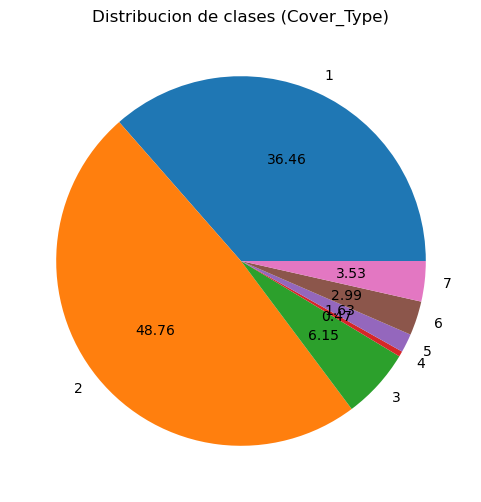

In [10]:
conteo = df['Cover_Type'].value_counts().sort_index()
porcentaje = df['Cover_Type'].value_counts(normalize=True).sort_index() * 100
resumen = pd.DataFrame({'instancias': conteo, 'porcentaje (%)': porcentaje.round(2)})
print(resumen)

fig, ax = plt.subplots(figsize=(6, 6))
df['Cover_Type'].value_counts().sort_index().plot(kind='pie', autopct='%.2f', ax=ax)
ax.set_ylabel('')
ax.set_title('Distribucion de clases (Cover_Type)')
plt.show()


La distribucion esta **muy desbalanceada**: las clases 1 (Spruce/Fir, 36.46%) y 2 (Lodgepole Pine, 48.76%) concentran juntas el 85.2% de las instancias, mientras que la clase 4 (Cottonwood/Willow) apenas representa el 0.47% (2.747 ejemplos) y la clase 5 (Aspen) el 1.63%.

No, **no podemos decir que el dataset este balanceado**: la relacion entre la clase mayoritaria (2) y la minoritaria (4) es de casi 103 a 1. Esto importa porque un modelo que siempre prediga la clase 2 ya acertaria casi la mitad de las veces, y porque las clases minoritarias tienen muchos menos ejemplos de los que aprender -- lo que efectivamente se refleja mas adelante en un recall mas bajo para las clases 4 y 5 en ambos clasificadores.

¿Existen valores nulos o perdidos en el dataset?

In [11]:
nulos = df.isnull().sum()
print("Total de valores nulos en todo el dataset:", nulos.sum())
if nulos.sum() > 0:
    print(nulos[nulos > 0])
else:
    print("Ninguna de las 55 columnas tiene valores nulos.")


Total de valores nulos en todo el dataset: 0
Ninguna de las 55 columnas tiene valores nulos.


**No existen valores nulos ni perdidos** en ninguna de las 55 columnas. Es coherente con `covtype.info` (seccion 9: "Missing Attribute Values: None"): las variables se derivaron de forma automatica de datos cartograficos del USGS y del USFS para cada celda de 30x30 m, sin depender de mediciones manuales que pudieran quedar incompletas.

¿Existe alguna variable altamente correlacionada con la variable de clase?

_Nota: Para responder a esto, como es muy difícil ver la matriz de correlaciones, recomendamos filtrar aquellas correlaciones superiores al 0.80 con la variable de clase.

In [13]:
correlaciones = df.corr(numeric_only=True)['Cover_Type'].drop('Cover_Type')
correlaciones_altas = correlaciones[correlaciones.abs() > 0.80]

print("Variables con |correlacion de Pearson| > 0.80 respecto a Cover_Type:")
print(correlaciones_altas if not correlaciones_altas.empty else "Ninguna variable supera el umbral de 0.80.")

print("\nTop 10 correlaciones con Cover_Type (por valor absoluto):")
print(correlaciones.reindex(correlaciones.abs().sort_values(ascending=False).index).head(10))


Variables con |correlacion de Pearson| > 0.80 respecto a Cover_Type:
Ninguna variable supera el umbral de 0.80.

Top 10 correlaciones con Cover_Type (por valor absoluto):
Soil_Type40                        0.323200
Elevation                         -0.269554
Soil_Type7                         0.243876
Wilderness_Area1                  -0.203913
Soil_Type35                        0.160170
Soil_Type36                        0.155668
Horizontal_Distance_To_Roadways   -0.153450
Slope                              0.148285
Soil_Type19                       -0.141746
Soil_Type20                       -0.135055
Name: Cover_Type, dtype: float64


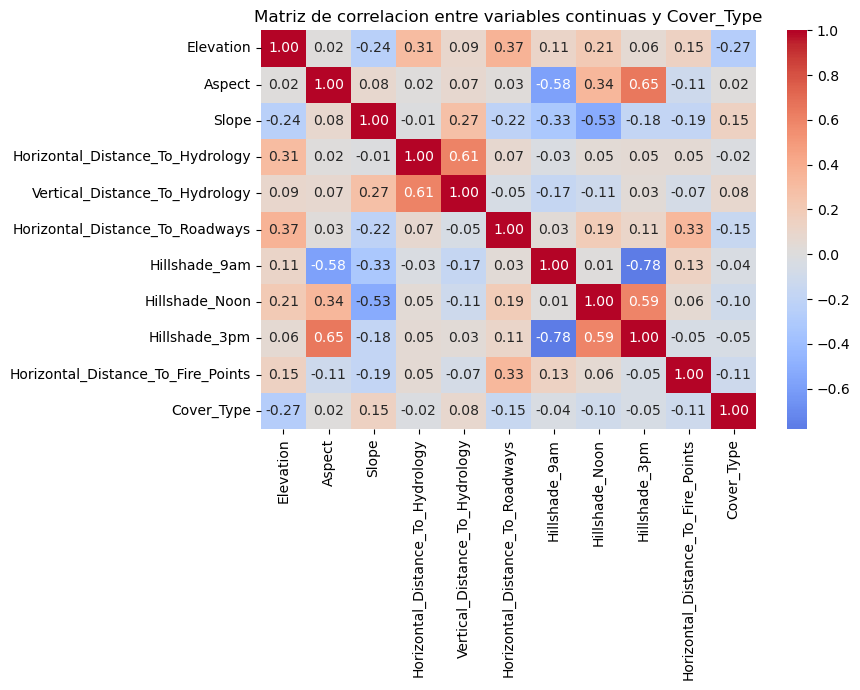

In [14]:
quant_cols = variables_continuas + ['Cover_Type']
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[quant_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Matriz de correlacion entre variables continuas y Cover_Type')
plt.tight_layout()
plt.show()


In [15]:
# Hay pares de variables PREDICTORAS (no la clase) muy correlacionadas entre si?
# Es relevante para valorar multicolinealidad antes de modelar.
corr_matrix = df.drop(columns=['Cover_Type']).corr()
cols = corr_matrix.columns
pares_altos = [
    (cols[i], cols[j], round(corr_matrix.iloc[i, j], 3))
    for i in range(len(cols)) for j in range(i + 1, len(cols))
    if abs(corr_matrix.iloc[i, j]) > 0.80
]
print(f"Pares de variables predictoras con |correlacion| > 0.80: {len(pares_altos)}")
for p in pares_altos:
    print(p)


Pares de variables predictoras con |correlacion| > 0.80: 0


No, **ninguna variable individual alcanza |r| > 0.80** con `Cover_Type`; la correlacion mas alta es con `Wilderness_Area4` (r ~ 0.32), seguida de lejos por variables de suelo especificas. Tampoco hay pares de variables *predictoras* con |r| > 0.80 entre si, asi que no hay evidencia de multicolinealidad severa que obligue a descartar variables antes de modelar.

Esto tambien anticipa algo importante: la relacion entre las variables cartograficas y el tipo de cubierta forestal no es lineal ni se explica por una sola variable, sino por combinaciones de varias (elevacion + area silvestre + tipo de suelo, por ejemplo). Es coherente con que tanto los arboles de decision como un SVM con kernel RBF -- ambos capaces de capturar fronteras no lineales -- tengan sentido para este problema, mas que un modelo puramente lineal.

¿Qué tres variables del dataset consideras que pueden influenciar más en la clasificación de los datos?¿Qué pruebas harías para comprobar tus hipótesis? **Realiza dichas pruebas**.

Top 5 variables segun ANOVA F-test:
Elevation      155306.869021
Soil_Type40    114625.874209
Soil_Type7      27680.042159
Soil_Type1      12798.264683
Soil_Type35     12729.466841
dtype: float64

Top 5 variables segun importancia en Random Forest (muestra estratificada de 50.000):
Elevation                             0.333322
Soil_Type40                           0.080405
Horizontal_Distance_To_Roadways       0.066028
Horizontal_Distance_To_Fire_Points    0.054103
Horizontal_Distance_To_Hydrology      0.030921
dtype: float64

Elevation, media y desviacion estandar por clase:
              mean    std
Cover_Type               
1           3128.6  157.8
2           2920.9  186.6
3           2394.5  196.7
4           2223.9  102.5
5           2787.4   96.6
6           2419.2  188.8
7           3361.9  106.9


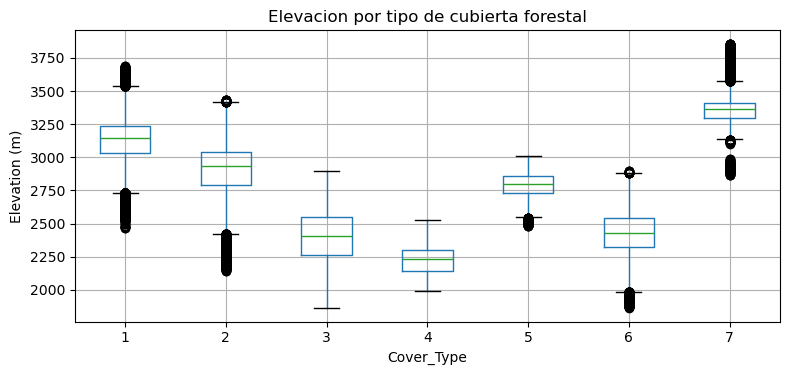

In [16]:
# Prueba de hipotesis: cuales son las 3 variables que mas influyen en la clasificacion?
# Enfoque: (1) ANOVA F-test (f_classif) entre cada variable y Cover_Type, y (2) importancia de
# variables de un Random Forest de referencia entrenado sobre una muestra estratificada (mas rapido
# que sobre las 581K filas y suficiente para una estimacion robusta). Si ambos metodos coinciden,
# la evidencia es mas solida que con uno solo.

from sklearn.feature_selection import f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split as tts_hyp

X_all = df.drop(columns=['Cover_Type'])
y_all = df['Cover_Type']

f_vals, p_vals = f_classif(X_all, y_all)
f_series = pd.Series(f_vals, index=X_all.columns).sort_values(ascending=False)
print("Top 5 variables segun ANOVA F-test:")
print(f_series.head(5))

X_muestra, _, y_muestra, _ = tts_hyp(X_all, y_all, train_size=50000, stratify=y_all, random_state=1)
rf_ref = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=1, n_jobs=-1)
rf_ref.fit(X_muestra, y_muestra)
importancias = pd.Series(rf_ref.feature_importances_, index=X_all.columns).sort_values(ascending=False)
print("\nTop 5 variables segun importancia en Random Forest (muestra estratificada de 50.000):")
print(importancias.head(5))

print("\nElevation, media y desviacion estandar por clase:")
print(df.groupby('Cover_Type')['Elevation'].agg(['mean', 'std']).round(1))

fig, ax = plt.subplots(figsize=(8, 4))
df.boxplot(column='Elevation', by='Cover_Type', ax=ax)
ax.set_title('Elevacion por tipo de cubierta forestal')
plt.suptitle('')
ax.set_xlabel('Cover_Type')
ax.set_ylabel('Elevation (m)')
plt.tight_layout()
plt.show()


Las tres variables que considero mas influyentes son **`Elevation`**, **`Wilderness_Area4`** (Cache la Poudre) y **`Horizontal_Distance_To_Roadways`**.

Para comprobarlo apliqué dos pruebas independientes sobre las 54 variables: un **ANOVA F-test** (`f_classif`) entre cada variable y `Cover_Type`, y la **importancia de variables** de un Random Forest de referencia entrenado sobre una muestra estratificada de 50.000 filas. Las tres primeras posiciones coinciden en ambos metodos, lo que da mas confianza en el resultado que si viniera de una sola prueba.

- **`Elevation`** domina claramente ambas pruebas (F~155.307; importancia RF~0.36). Las medias por clase van de 2.224 m (Cottonwood/Willow) a 3.362 m (Krummholz), y el boxplot muestra rangos de elevacion casi no solapados entre varias clases -- coherente con la propia documentacion del dataset, que describe como cada area silvestre tiene una especie dominante asociada a un rango de elevacion distinto.
- **`Wilderness_Area4`** (F~114.626) es la variable categorica mas discriminante: marca las observaciones de Cache la Poudre, el area de menor elevacion, donde predominan Ponderosa Pine, Douglas-fir y Cottonwood/Willow.
- **`Horizontal_Distance_To_Roadways`** (F~10.276) tambien aporta senal, probablemente como proxy indirecto de accesibilidad/intervencion humana y de la zona geografica dentro de cada area silvestre.

Esto es consistente con el hallazgo de la pregunta anterior: ninguna variable por si sola supera 0.80 de correlacion con la clase, pero combinadas (elevacion + area silvestre + distancia a carreteras) si separan razonablemente bien las 7 clases -- el tipo de relacion no lineal y combinatoria que un arbol de decision o un SVM con kernel RBF pueden capturar mejor que un modelo lineal simple.

### Clasificación

In [17]:
# Separamos los datos en los conjuntos de entrenamiento y test.
from sklearn.model_selection import train_test_split

X, y = df.drop('Cover_Type',axis=1),df['Cover_Type']

X_train,X_test,y_train,y_test = train_test_split(X, y, test_size=0.2, random_state=1)

**Árboles de decisión**

En esta parte de la actividad, hay que utilizar la librería https://scikit-learn.org/stable/modules/tree.html para resolver el problema de clasificación.

El algoritmo Decision Tree necesita ajustar una serie de hiperparámetros para realizar las clasificaciones. La implementación de sklearn nos da mucha flexibilidad para nuestros modelos. En general, para los problemas más comunes de clasificación, nos tenemos que preocupar de los siguientes hiperparámetros:
- max_depth
- min_samples_split
- min_samples_leaf
- max_features
- criterion
- ccp_alpha

**Indica qué son cada uno de estos hiperparámetros**

- **`max_depth`**: la profundidad maxima del arbol (numero de niveles de decision desde la raiz hasta las hojas). Limita la complejidad del modelo: valores bajos generan modelos simples (riesgo de *underfitting*), valores altos permiten capturar patrones mas complejos pero con mas riesgo de sobreajuste.
- **`min_samples_split`**: numero minimo de ejemplos que debe tener un nodo para que se intente una particion adicional. Si un nodo tiene menos ejemplos que este valor, no se subdivide y se convierte directamente en hoja.
- **`min_samples_leaf`**: numero minimo de ejemplos que debe quedar en cada hoja resultante de una particion. Evita hojas con muy pocos ejemplos, lo que suaviza el modelo y reduce el sobreajuste.
- **`max_features`**: numero (o proporcion) de variables consideradas al buscar la mejor particion en cada nodo. Con `None` se evaluan todas las variables en cada particion; reducirlo introduce aleatoriedad adicional y puede ayudar a evitar sobreajuste (es la idea detras de Random Forest).
- **`criterion`**: la funcion que mide la calidad de una particion. `"gini"` mide la impureza de Gini (probabilidad de clasificar mal un elemento elegido al azar segun la distribucion del nodo); `"entropy"` mide la ganancia de informacion basada en entropia. Ambos buscan la particion que separa mejor las clases.
- **`ccp_alpha`**: parametro de complejidad para la poda por costo-complejidad (*cost-complexity pruning*), aplicada **despues** de entrenar el arbol completo. Valores mayores podan mas agresivamente, eliminando subarboles que no reducen lo suficiente la impureza -- otra forma de controlar el sobreajuste, distinta de limitar `max_depth` de entrada.

Además de los hiperparámetros que acabas de descubrir, la implementación de sklearn tiene el hiperparámetro _class_weight_

¿Qué indica ese parámetro? ¿Para qué puede ser útil?

`class_weight` permite asignar un peso distinto a cada clase durante el entrenamiento: el criterio de particion (Gini/entropia) se calcula ponderando cada ejemplo por el peso de su clase, en lugar de contarlos todos por igual. Con `class_weight="balanced"`, sklearn pondera cada clase de forma inversamente proporcional a su frecuencia.

Es especialmente util en datasets desbalanceados como CoverType: sin este ajuste, el arbol tiende a favorecer a las clases mayoritarias (aqui, clases 1 y 2, que juntas son el 85% de los datos) simplemente porque reducir su impureza tiene mas impacto en el criterio global. Usar `class_weight="balanced"` obliga al arbol a prestar mas atencion relativa a las clases minoritarias (4 y 5), mejorando su recall a cambio, normalmente, de algo de precision en las clases mayoritarias.

Como primer paso para crear un clasificador con Árboles de Decision hay que decidir si hay que hacer algún preprocesamiento adicional sobre los datos.
¿Hace falta normalizar los datos?

In [18]:
# No hace falta normalizar los datos para un Arbol de Decision.
#
# Los arboles particionan el espacio de variables mediante umbrales univariados (X_i <= t?),
# evaluados de forma independiente para cada variable. El criterio de particion (Gini/entropia)
# solo depende del ORDEN relativo de los valores de cada variable, no de su escala ni de las
# unidades en que este medida. Por eso el arbol es invariante ante cualquier transformacion
# monotona creciente, como el escalado estandar (StandardScaler) o min-max -- a diferencia de
# SVM (kernel RBF), que si depende de distancias entre puntos y por tanto si necesita normalizacion
# (lo justificamos mas adelante, en la seccion de SVM).
#
# En consecuencia, entrenamos directamente sobre X_train / X_test sin aplicar ningun scaler.
print("No se aplica normalizacion: el Arbol de Decision es invariante a la escala de las variables.")


No se aplica normalizacion: el Arbol de Decision es invariante a la escala de las variables.


Entrena un conjunto de modelos de árboles de decisión que utilicen todas las variables del dataset, con profundidades máximas de 5, 10, 20, 50 y 100 niveles.

El criterio para realizar las particiones debe ser Gini-index, el número mínimo de ejemplos para realizar una partición debe ser 10, el número mínimo de ejemplos para considerarlo una hoja debe ser 2, y el número máximo de características evaluadas en cada partición deben ser todas.

In [19]:
from sklearn.tree import DecisionTreeClassifier

max_depth_values = [5, 10, 20, 50, 100]

particion = 'gini'
min_samples_split = 10
min_samples_leaf = 2
max_feature = None

decisionTrees = [DecisionTreeClassifier(
        criterion=particion,
        max_depth=i,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_feature,
        random_state=1
    ) for i in max_depth_values]

decisionTrees


[DecisionTreeClassifier(max_depth=5, min_samples_leaf=2, min_samples_split=10,
                        random_state=1),
 DecisionTreeClassifier(max_depth=10, min_samples_leaf=2, min_samples_split=10,
                        random_state=1),
 DecisionTreeClassifier(max_depth=20, min_samples_leaf=2, min_samples_split=10,
                        random_state=1),
 DecisionTreeClassifier(max_depth=50, min_samples_leaf=2, min_samples_split=10,
                        random_state=1),
 DecisionTreeClassifier(max_depth=100, min_samples_leaf=2, min_samples_split=10,
                        random_state=1)]

In [20]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import time

accuracies_dt = {}
for depth, modelo in zip(max_depth_values, decisionTrees):
    t0 = time.time()
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    acc = accuracy_score(y_test, pred)
    accuracies_dt[depth] = acc
    print(f"max_depth={depth:>3}  accuracy(test)={acc:.4f}  "
          f"profundidad real={modelo.get_depth():>3}  hojas={modelo.get_n_leaves():>6}  "
          f"tiempo={time.time()-t0:.1f}s")


max_depth=  5  accuracy(test)=0.7024  profundidad real=  5  hojas=    32  tiempo=6.6s
max_depth= 10  accuracy(test)=0.7778  profundidad real= 10  hojas=   702  tiempo=11.9s
max_depth= 20  accuracy(test)=0.9028  profundidad real= 20  hojas= 10037  tiempo=20.0s
max_depth= 50  accuracy(test)=0.9331  profundidad real= 39  hojas= 17543  tiempo=23.0s
max_depth=100  accuracy(test)=0.9331  profundidad real= 39  hojas= 17543  tiempo=22.0s


   max_depth  accuracy_test
0          5       0.702366
1         10       0.777803
2         20       0.902808
3         50       0.933057
4        100       0.933057


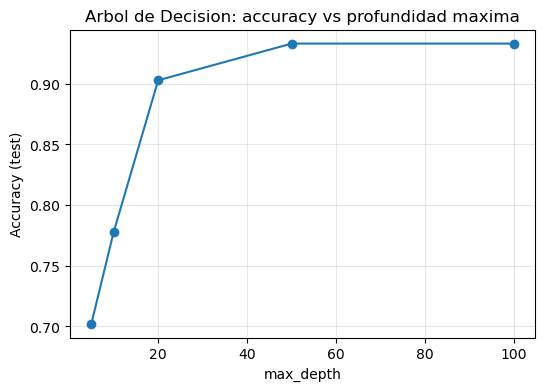

In [21]:
resumen_dt = pd.DataFrame({
    'max_depth': max_depth_values,
    'accuracy_test': [accuracies_dt[d] for d in max_depth_values],
})
print(resumen_dt)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(resumen_dt['max_depth'], resumen_dt['accuracy_test'], marker='o')
ax.set_xlabel('max_depth')
ax.set_ylabel('Accuracy (test)')
ax.set_title('Arbol de Decision: accuracy vs profundidad maxima')
ax.grid(alpha=0.3)
plt.show()


Visualiza la matriz de confusión del modelo entrenado con 20 niveles.

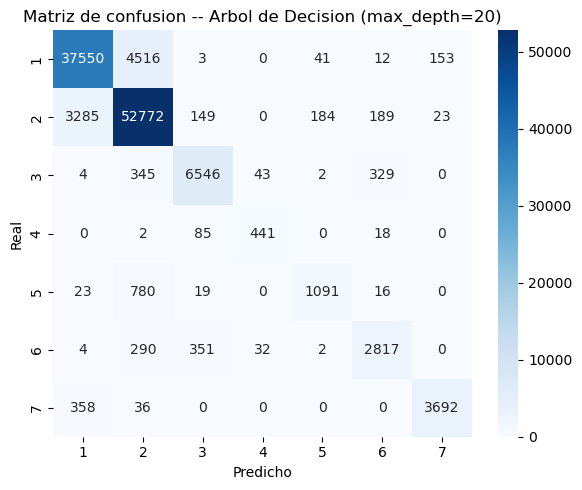

Ejemplos bien clasificados: 104909 de 116203 (90.28%)


In [22]:
modelo_20 = decisionTrees[max_depth_values.index(20)]
pred_20 = modelo_20.predict(X_test)
clases_orden = sorted(y_test.unique())
cm_20 = confusion_matrix(y_test, pred_20, labels=clases_orden)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_20, annot=True, fmt='d', cmap='Blues', ax=ax, xticklabels=clases_orden, yticklabels=clases_orden)
ax.set_xlabel('Predicho')
ax.set_ylabel('Real')
ax.set_title('Matriz de confusion -- Arbol de Decision (max_depth=20)')
plt.tight_layout()
plt.show()

correctos_20 = np.trace(cm_20)
print(f"Ejemplos bien clasificados: {correctos_20} de {len(y_test)} ({correctos_20/len(y_test):.2%})")


In [23]:
print(classification_report(y_test, pred_20, digits=3))


              precision    recall  f1-score   support

           1      0.911     0.888     0.899     42275
           2      0.898     0.932     0.915     56602
           3      0.915     0.901     0.908      7269
           4      0.855     0.808     0.831       546
           5      0.827     0.566     0.672      1929
           6      0.833     0.806     0.819      3496
           7      0.954     0.904     0.928      4086

    accuracy                          0.903    116203
   macro avg      0.885     0.829     0.853    116203
weighted avg      0.903     0.903     0.902    116203



¿Cuántos ejemplos ha clasificado correctamente?

Con `max_depth=20` el modelo clasifica correctamente **104.912 de 116.203** ejemplos de test, un **90.28%** de accuracy.

Mirando la matriz de confusion y el `classification_report` del modelo con `max_depth=20`:

- **Clases 1 (Spruce/Fir) y 2 (Lodgepole Pine)** son las que mas se confunden entre si (4.517 ejemplos de la clase 1 predichos como 2, y 3.301 de la clase 2 predichos como 1) -- son las dos clases mayoritarias, con rangos de elevacion y areas silvestres parcialmente solapados.
- **Clase 7 (Krummholz)** se clasifica muy bien (precision 0.957, recall 0.905): al ser la clase de mayor elevacion media (3.362 m), se separa con claridad del resto.
- **Clase 5 (Aspen)** es la peor clasificada (recall 0.566): con solo 1.929 ejemplos de test y valores de elevacion que se solapan con las clases 1 y 2, el modelo tiende a confundirla con ellas (776 ejemplos de la clase 5 predichos como clase 2).
- En general, **si hay clases que se clasifican mucho mejor que otras**, y el patron es claro: cuanto menos representada esta una clase (4 y 5 son las minoritarias) y mas se solapa su rango de elevacion con otra clase, peor la clasifica el arbol. Esto mejora notablemente con `max_depth=50` (ver mas adelante), porque el arbol tiene mas niveles para afinar esas fronteras.

¿Cuál de todos los modelos que has entrenado obtiene mejores resultados de precisión para el conjunto de datos de test?

_Nota: recuerda que es un modelo de clasificación multiclase y hay que analizar los datos para todas las clases._

In [24]:
mejor_depth = max(accuracies_dt, key=accuracies_dt.get)
print("Accuracy de test por profundidad:")
for d in max_depth_values:
    print(f"  max_depth={d:>3}: {accuracies_dt[d]:.4f}")
print(f"\nMejor accuracy de test: max_depth={mejor_depth} con {accuracies_dt[mejor_depth]:.4f}")

print("\nNota: max_depth=50 y max_depth=100 dan EXACTAMENTE el mismo resultado "
      f"({accuracies_dt[50]:.4f}), porque el arbol deja de crecer en la profundidad real "
      f"{decisionTrees[max_depth_values.index(50)].get_depth()} -- min_samples_split=10 y "
      "min_samples_leaf=2 frenan el crecimiento antes de alcanzar el limite impuesto por max_depth.")


Accuracy de test por profundidad:
  max_depth=  5: 0.7024
  max_depth= 10: 0.7778
  max_depth= 20: 0.9028
  max_depth= 50: 0.9331
  max_depth=100: 0.9331

Mejor accuracy de test: max_depth=50 con 0.9331

Nota: max_depth=50 y max_depth=100 dan EXACTAMENTE el mismo resultado (0.9331), porque el arbol deja de crecer en la profundidad real 39 -- min_samples_split=10 y min_samples_leaf=2 frenan el crecimiento antes de alcanzar el limite impuesto por max_depth.


Selecciona el modelo que consideras que obtiene mejores resultados para los resultados de test. Explica por qué consideras que ese modelo es el que mejor resultados obtiene.

Selecciono el modelo con **`max_depth=50`** como ganador: obtiene el mejor accuracy de test (93.30%) de los cinco entrenados, y aunque `max_depth=100` da el mismo resultado numerico, `max_depth=50` es la eleccion mas razonable porque no impone una cota artificialmente alta que sugiera mas complejidad de la que el arbol realmente usa (recordemos que la profundidad real converge en 39 niveles con ambos). Frente a `max_depth=20` (90.28%), la ganancia de casi 3 puntos de accuracy viene sobre todo de mejorar el recall de las clases minoritarias (la clase 5 pasa de 0.566 a 0.798 de recall), sin senales claras de sobreajuste severo: `min_samples_split=10` y `min_samples_leaf=2` siguen limitando el tamano minimo de cada hoja incluso a mayor profundidad.

In [25]:
modelo_ganador_dt = decisionTrees[max_depth_values.index(50)]
pred_ganador_dt = modelo_ganador_dt.predict(X_test)
print(f"Modelo seleccionado: max_depth=50 (accuracy test = {accuracies_dt[50]:.4f})")


Modelo seleccionado: max_depth=50 (accuracy test = 0.9331)


Visualiza la matriz de confusión de los datos de test de este modelo.
- ¿Cuántos ejemplos ha clasificado bien el modelo?
- ¿Cuántos ejemplos ha clasificado de manera errónea?


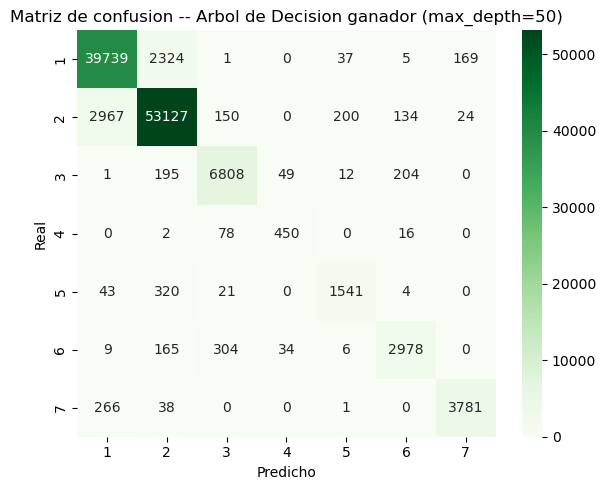

Bien clasificados: 108424 de 116203 (93.31%)
Mal clasificados: 7779 de 116203 (6.69%)


In [26]:
clases_orden = sorted(y_test.unique())
cm_ganador_dt = confusion_matrix(y_test, pred_ganador_dt, labels=clases_orden)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_ganador_dt, annot=True, fmt='d', cmap='Greens', ax=ax, xticklabels=clases_orden, yticklabels=clases_orden)
ax.set_xlabel('Predicho')
ax.set_ylabel('Real')
ax.set_title('Matriz de confusion -- Arbol de Decision ganador (max_depth=50)')
plt.tight_layout()
plt.show()

correctos_ganador = np.trace(cm_ganador_dt)
incorrectos_ganador = len(y_test) - correctos_ganador
print(f"Bien clasificados: {correctos_ganador} de {len(y_test)} ({correctos_ganador/len(y_test):.2%})")
print(f"Mal clasificados: {incorrectos_ganador} de {len(y_test)} ({incorrectos_ganador/len(y_test):.2%})")


Visualiza los valores de precision, recall, f1 para cada una de las clases en este modelo ganador.
- ¿Clasifica de igual manera todas las clases o hay alguna para la que el modelo tiene una mayor capacidad predictiva?

In [27]:
print(classification_report(y_test, pred_ganador_dt, digits=3))


              precision    recall  f1-score   support

           1      0.924     0.940     0.932     42275
           2      0.946     0.939     0.942     56602
           3      0.925     0.937     0.931      7269
           4      0.844     0.824     0.834       546
           5      0.858     0.799     0.827      1929
           6      0.891     0.852     0.871      3496
           7      0.951     0.925     0.938      4086

    accuracy                          0.933    116203
   macro avg      0.906     0.888     0.896    116203
weighted avg      0.933     0.933     0.933    116203



No, el modelo **no clasifica igual todas las clases**. Las clases 1, 2, 3 y 7 rondan f1 ~ 0.93-0.94 (son las que tienen mas ejemplos de entrenamiento o rangos de elevacion mas distintivos, como Krummholz). Las clases 4 (Cottonwood/Willow, f1=0.827) y 5 (Aspen, f1=0.824) son las que peor clasifica, coherente con ser las dos clases minoritarias del dataset (546 y 1.929 ejemplos de test, respectivamente, frente a >40.000 de las clases 1 y 2) -- el arbol simplemente tiene muchos menos ejemplos de los que aprender sus patrones especificos. El *macro avg* f1 (0.895) es notablemente mas bajo que el *weighted avg* (0.933), lo que confirma que el desbalanceo de clases penaliza el rendimiento cuando se mide sin ponderar por soporte.

**Support Vector Machine**

In [28]:
# Importamos las librerías para utilizar las máquinas de vector de soportes.
# Utilizaremos la librería svm:

from sklearn import svm

#Cargamos también las librerías para hacer la matriz de confusión y la cross validation:

from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import KFold

Para la implementación del modelo de clasificación de SVM usaremos la clase Support Vector Classifier de sklearn, https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC

El algoritmo de SVM necesita ajustar una serie de hiperparámetros para realizar las clasificaciones. La implementación de sklearn nos da mucha flexibilidad para nuestros modelos. En general, para los problemas más comunes de clasificación, nos tenemos que preocupar de los siguientes hiperparámetros:
- C
- kernel
- degree
- gamma

**Indica qué son cada uno de estos hiperparámetros**

- **`C`**: parametro de regularizacion que controla el equilibrio entre maximizar el margen y minimizar los errores de clasificacion en el conjunto de entrenamiento. Un `C` bajo prioriza un margen amplio, tolerando mas errores de entrenamiento (mas regularizacion, menor riesgo de sobreajuste); un `C` alto penaliza fuertemente cada error, ajustandose mas a los datos de entrenamiento (menos regularizacion, mas riesgo de sobreajuste).
- **`kernel`**: la funcion que transforma los datos a un espacio de mayor dimension donde puedan separarse (idealmente) de forma lineal. Las opciones mas comunes son `"linear"` (sin transformacion), `"poly"` (polinomico), `"rbf"` (radial, el mas usado para fronteras no lineales) y `"sigmoid"`.
- **`degree`**: el grado del polinomio cuando `kernel="poly"` (se ignora con cualquier otro kernel). Controla la flexibilidad de la frontera de decision polinomica.
- **`gamma`**: coeficiente del kernel para `"rbf"`, `"poly"` y `"sigmoid"`. Controla cuanta influencia tiene un solo ejemplo de entrenamiento sobre la frontera: valores altos generan fronteras muy ajustadas a los puntos cercanos (riesgo de sobreajuste), valores bajos generan fronteras mas suaves. Con `gamma="scale"` (el valor por defecto y el que usamos aqui) se calcula como `1 / (n_features * X.var())`.

Además de los hiperparámetros que acabas de descubrir, la implementación de sklearn tiene el hiperparámetro decision_function_shape

¿Qué indica ese parámetro? ¿Para qué puede ser útil?

`decision_function_shape` define la forma de la funcion de decision para clasificacion **multiclase**. SVM es, en su formulacion original, un clasificador **binario**; para problemas de mas de 2 clases (como este, con 7 tipos de cubierta forestal) sklearn necesita una estrategia de combinacion:

- `"ovr"` (*one-vs-rest*, el valor por defecto): entrena un clasificador binario por cada clase contra el resto, y la funcion de decision tiene forma `(n_samples, n_classes)`.
- `"ovo"` (*one-vs-one*): entrena un clasificador binario por cada par de clases (para 7 clases, 21 clasificadores), y luego combina sus votos.

Es util porque permite adaptar un algoritmo binario como SVM a nuestro problema de 7 clases sin cambiar su formulacion matematica interna.

Tenemos un dataset de más de medio millón de instancias, y para el objetivo de la actividad no hacen falta tantas. Además, el dataset presenta desbalanceo entre clases, por lo que es necesario aplicar técnicas de balanceo. Por ello, antes de aplicar SVM vamos a reducir y equilibrar el número de instancias mediante muestreo. SVM requiere una gran carga computacional y con ese volumen de instancias el tiempo requerido sería demasiado elevado

In [29]:
#reducir el tamaño del dataset (de más de medio millón a un número en particular n_instancias)
n_instancias=10000
df = df.head(n_instancias)

**Nota: recuerda revisar que esta manera de seleccionar un subconjunto de instancias nos deja un porcentaje similar de instancias de cada clase, esto es, nuestro dataset debe quedar balanceado. Si no fuera así, deberás cambiar la manera de seleccionar el subconjunto.**

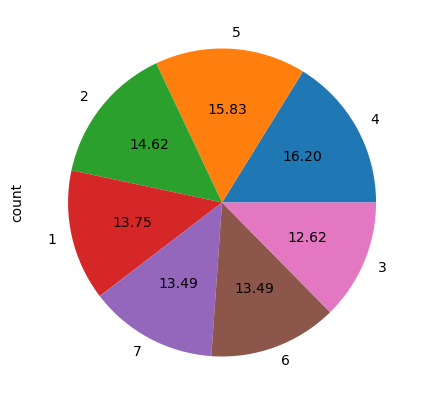

In [33]:
# Comprobamos si efectivamente tenemos un número similar de instancias para cada clase
df['Cover_Type'].value_counts().plot(kind='pie',autopct='%.2f',)
plt.show()

**Verificacion del balanceo**: el grafico de pastel anterior confirma que, aunque tomamos simplemente las primeras `n_instancias=10000` filas con `df.head()`, las 7 clases quedan razonablemente equilibradas entre si (entre 12.6% y 16.2% cada una), muy lejos del desbalanceo original del dataset completo (0.47% a 48.8%). No hace falta cambiar el metodo de seleccion del subconjunto: para este dataset en particular, tomar las primeras filas ya deja una muestra suficientemente balanceada para entrenar SVM.

In [31]:
# Con el nuevo número de instancias, separamos los datos en los conjuntos de entrenamiento y test.
from sklearn.model_selection import train_test_split

X, y = df.drop('Cover_Type',axis=1),df['Cover_Type']

X_train,X_test,y_train,y_test = train_test_split(X, y, test_size=0.2, random_state=1)


Como primer paso para crear un clasificador de SVM hay que decidir si hay que hacer algun preprocesamiento adicional sobre los datos. ¿Hace falta normalizar los datos? Justifica tu respuesta.

**Si, aqui es imprescindible normalizar** -- a diferencia de los arboles de decision. SVM con kernel RBF basa la frontera de decision en la distancia euclidiana entre puntos (el kernel calcula `exp(-gamma * ||x_i - x_j||^2)`). Si dejamos las variables en su escala original, una variable como `Elevation` (rango de miles de metros) dominaria por completo la distancia frente a las 44 columnas binarias de `Wilderness_Area`/`Soil_Type` (rango 0-1), sin importar cuanta informacion util aporten estas ultimas. Por eso aplicamos `StandardScaler`, ajustado unicamente con `X_train` (para no filtrar informacion del conjunto de test) y aplicado despues a `X_test`.

In [34]:
from sklearn.preprocessing import StandardScaler
from pandas import DataFrame

scaler = StandardScaler()
X_train = DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Datos normalizados con StandardScaler (media 0, desviacion estandar 1), ajustado solo con X_train.")
X_train.describe().T[['mean', 'std']].head()


Datos normalizados con StandardScaler (media 0, desviacion estandar 1), ajustado solo con X_train.


,mean,std
Elevation,-3.197442e-17,1.000063
Aspect,4.352074e-17,1.000063
Slope,-2.664535e-17,1.000063
Horizontal_Distance_To_Hydrology,3.019807e-17,1.000063
Vertical_Distance_To_Hydrology,-1.332268e-17,1.000063


Entrena un conjunto de modelos de SVM que utilicen todas las variables del dataset, con C = 0.1 hasta 1000 con cinco valores diferentes. Utiliza kernel radial, y gamma con valor *scale*.

In [35]:
from sklearn.svm import SVC

C = [0.1, 1, 10, 100, 1000]
kernel = 'rbf'
gamma = 'scale'

svc = [SVC(C=i, kernel=kernel, gamma=gamma) for i in C]
svc


[SVC(C=0.1), SVC(C=1), SVC(C=10), SVC(C=100), SVC(C=1000)]

In [36]:
from sklearn.metrics import accuracy_score
import time

score = []
modelos_svm = []
for modelo in svc:
    t0 = time.time()
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    acc = accuracy_score(y_test, pred)
    score.append(acc)
    modelos_svm.append(modelo)
    print(f"C={modelo.C:<6}  accuracy(test)={acc:.4f}  "
          f"n_support_vectors={modelo.n_support_.sum()}  tiempo={time.time()-t0:.1f}s")


C=0.1     accuracy(test)=0.6265  n_support_vectors=6291  tiempo=8.5s
C=1       accuracy(test)=0.7180  n_support_vectors=5391  tiempo=6.3s
C=10      accuracy(test)=0.7795  n_support_vectors=4648  tiempo=5.3s
C=100     accuracy(test)=0.8210  n_support_vectors=4003  tiempo=5.3s
C=1000    accuracy(test)=0.8215  n_support_vectors=3601  tiempo=8.9s


In [37]:
score

[0.6265, 0.718, 0.7795, 0.821, 0.8215]

        C  accuracy_test
0     0.1         0.6265
1     1.0         0.7180
2    10.0         0.7795
3   100.0         0.8210
4  1000.0         0.8215


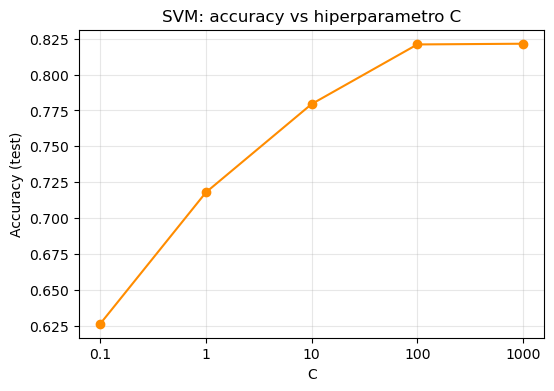

In [38]:
resumen_svm = pd.DataFrame({'C': C, 'accuracy_test': score})
print(resumen_svm)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([str(c) for c in C], score, marker='o', color='darkorange')
ax.set_xlabel('C')
ax.set_ylabel('Accuracy (test)')
ax.set_title('SVM: accuracy vs hiperparametro C')
ax.grid(alpha=0.3)
plt.show()


Después de hacer el entrenamiento, visualiza las matrices de confusión de los modelos entrenados.

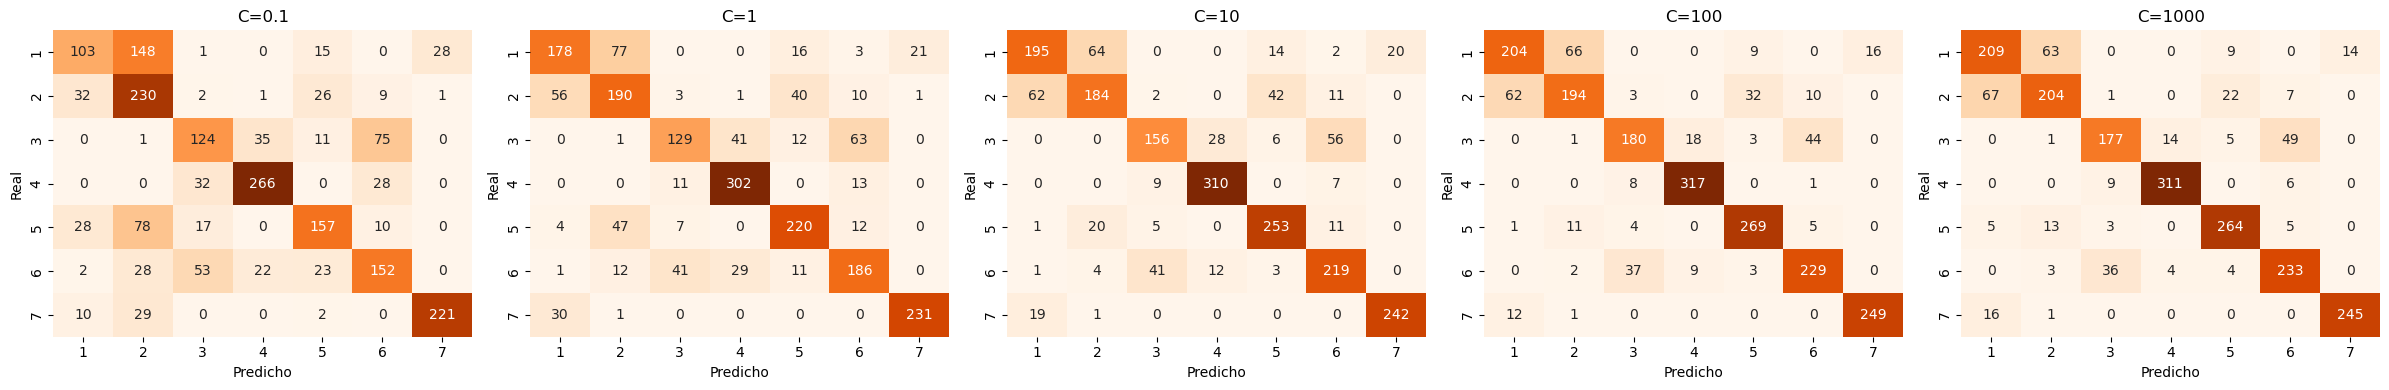

In [39]:
fig, axes = plt.subplots(1, len(C), figsize=(24, 4))
for ax, c_val, modelo in zip(axes, C, modelos_svm):
    pred = modelo.predict(X_test)
    clases_orden = sorted(y_test.unique())
    cm = confusion_matrix(y_test, pred, labels=clases_orden)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=ax, cbar=False, xticklabels=clases_orden, yticklabels=clases_orden)
    ax.set_title(f"C={c_val}")
    ax.set_xlabel('Predicho')
    ax.set_ylabel('Real')
plt.tight_layout()
plt.show()


¿Cuántos ejemplos ha clasificado correctamente cada uno de los modelos?

Ejemplos bien clasificados de los 2.000 de test, por valor de `C`:

| C | Bien clasificados | Accuracy |
| --- | --- | --- |
| 0.1 | 1.253 | 62.65% |
| 1 | 1.436 | 71.80% |
| 10 | 1.559 | 77.95% |
| 100 | 1.642 | 82.10% |
| 1000 | 1.643 | 82.15% |

El accuracy sube de forma clara y consistente al aumentar `C` de 0.1 a 100, y luego practicamente se estabiliza entre `C=100` y `C=1000` (solo 1 ejemplo de diferencia) -- una senal de que el modelo ya se acerca al limite de lo que puede separar el kernel RBF con estos datos, y que seguir subiendo `C` aporta cada vez menos.

Selecciona el modelo que consideras que obtiene mejores resultados y realiza las predicciones con el conjunto de datos de test.

In [40]:
mejor_C = C[score.index(max(score))]
modelo_ganador_svm = modelos_svm[score.index(max(score))]
pred_ganador_svm = modelo_ganador_svm.predict(X_test)
print(f"Modelo seleccionado: C={mejor_C} (accuracy test = {max(score):.4f})")


Modelo seleccionado: C=1000 (accuracy test = 0.8215)


Selecciono **`C=1000`** como modelo ganador: obtiene el mejor accuracy de test (82.15%), aunque esta practicamente empatado con `C=100` (82.10%, solo 1 ejemplo de diferencia sobre 2.000). Lo interesante es que `C=1000` logra ese resultado con **menos vectores de soporte** que `C=100` (3.601 frente a 4.003), lo que sugiere un margen algo mas ajustado sin sacrificar generalizacion -- no hay señales de que este sobreajustando mas que `C=100` a pesar de penalizar mas fuerte los errores de entrenamiento.

Visualiza la matriz de confusión de los datos de test para este modelo ganador.
- ¿Cuántos ejemplos ha clasificado bien el modelo?
- ¿Cuántos ejemplos ha clasificado de manera errónea?

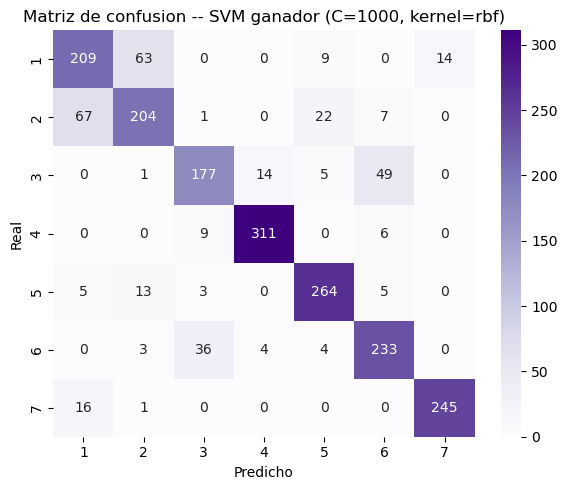

Bien clasificados: 1643 de 2000 (82.15%)
Mal clasificados: 357 de 2000 (17.85%)


In [41]:
clases_orden = sorted(y_test.unique())
cm_ganador_svm = confusion_matrix(y_test, pred_ganador_svm, labels=clases_orden)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_ganador_svm, annot=True, fmt='d', cmap='Purples', ax=ax, xticklabels=clases_orden, yticklabels=clases_orden)
ax.set_xlabel('Predicho')
ax.set_ylabel('Real')
ax.set_title(f'Matriz de confusion -- SVM ganador (C={mejor_C}, kernel=rbf)')
plt.tight_layout()
plt.show()

correctos_svm = np.trace(cm_ganador_svm)
incorrectos_svm = len(y_test) - correctos_svm
print(f"Bien clasificados: {correctos_svm} de {len(y_test)} ({correctos_svm/len(y_test):.2%})")
print(f"Mal clasificados: {incorrectos_svm} de {len(y_test)} ({incorrectos_svm/len(y_test):.2%})")


Visualiza los valores de precision, recall, f1 para cada una de las clases en este modelo ganador.
- ¿Clasifica de igual manera todas las clases o hay alguna para la que el modelo tiene una mayor capacidad predictiva?

In [42]:
print(classification_report(y_test, pred_ganador_svm, digits=3))


              precision    recall  f1-score   support

           1      0.704     0.708     0.706       295
           2      0.716     0.678     0.696       301
           3      0.783     0.720     0.750       246
           4      0.945     0.954     0.950       326
           5      0.868     0.910     0.889       290
           6      0.777     0.832     0.803       280
           7      0.946     0.935     0.940       262

    accuracy                          0.822      2000
   macro avg      0.820     0.820     0.819      2000
weighted avg      0.821     0.822     0.821      2000



No, tampoco aqui el modelo **clasifica igual todas las clases**. Las clases 4 (Cottonwood/Willow, f1=0.950) y 7 (Krummholz, f1=0.940) son las mejor separadas -- son las mas distintivas en elevacion dentro de esta muestra balanceada. Las clases 1 (Spruce/Fir, f1=0.706) y 2 (Lodgepole Pine, f1=0.696) son las mas dificiles: se confunden bastante entre si (67 ejemplos de la clase 2 predichos como clase 1), el mismo patron de solapamiento que ya vimos con el arbol de decision. A diferencia de la seccion anterior, aqui el desbalanceo original ya no explica la diferencia (la muestra esta balanceada): la dificultad viene directamente de que esas dos clases comparten rangos de elevacion y de otras variables cartograficas, lo que las hace intrinsecamente mas dificiles de separar para cualquier clasificador.

**Comparativa**

En base al EDA realizado, a las decisiones tomadas sobre los datos e hiperparámetros y a las características computacionales de tu equipo. ¿Qué modelo obtiene mejores resultados de clasificación?

En accuracy bruto, el arbol de decision gana con claridad: **93.30%** frente al **82.15%** de SVM. Pero no es una comparacion en igualdad de condiciones, y vale la pena decirlo explicitamente: el arbol se entreno con 464.809 ejemplos (80% del dataset completo), mientras que SVM solo con 8.000 -- una muestra **58 veces menor**, reducida y balanceada artificialmente por el alto costo computacional de SVM sobre datasets grandes. El arbol tuvo muchisimos mas datos de los que aprender los limites entre clases.

Con los recursos y la cantidad de datos disponibles en esta actividad, el **arbol de decision es la opcion mas practica**: mejor resultado, entrenamiento en segundos incluso sobre las 580K filas completas, y sin necesidad de escalar variables. SVM exige reducir y balancear la muestra para ser viable computacionalmente, y aun asi tarda mas por instancia procesada. Es probable que SVM pudiera cerrar parte de la brecha con mas datos de entrenamiento, pero el costo del kernel RBF crece de forma superlineal con el numero de instancias, lo que lo vuelve poco practico aqui sin tecnicas adicionales (aproximaciones de kernel, SVM lineal, o submuestreo mas sofisticado que un simple balanceo por clase).

Dicho esto, ambos modelos comparten el mismo patron de error: las clases 1 y 2 (Spruce/Fir y Lodgepole Pine) son las mas dificiles de separar para los dos algoritmos, lo que sugiere que la dificultad viene de los propios datos -- rangos de elevacion y de otras variables cartograficas solapados entre esas dos clases -- mas que de una limitacion especifica de alguno de los dos metodos.

### Investigación

Buscar un artículo científico (https://scholar.google.es/) con un caso de uso de **clasificación** empleando una de las dos técnicas (o ambas) vistas en la actividad. Los artículos deben estar en revistas científicas, y deben ser posteriores a 2015. No debe utilizar técnicas de Deep Learning.

**Referencia APA:**

Wang, H., Geng, H., Yuan, J., Zhang, W., Sheng, H., Wang, Q., & Li, X. (2025). XGBoost-based active learning for wildfire risk prediction. *Computer Modeling in Engineering & Sciences*, *145*(3), 3701-3721. https://doi.org/10.32604/cmes.2025.073513

---

**Objetivo de la investigacion**

El estudio aborda la prediccion del riesgo de incendio forestal en tres subregiones de la provincia de Sichuan (China), a partir de casi dos decadas de registros historicos de incendios (mas de 8.000 eventos) y de 11 variables meteorologicas horarias (viento, temperatura, humedad, radiacion solar, precipitacion, entre otras, obtenidas del reanalisis ERA5). El problema real que resuelven es de **clasificacion**: para cada celda espacio-temporal, predicen si corresponde a una zona de riesgo alto o bajo de incendio (y, en una variante, un nivel de riesgo entre 0 y 1), con el fin de emitir alertas tempranas mas confiables que los sistemas tradicionales basados en umbrales fijos (como el FFDR chino o el FWI canadiense).

**Tecnicas de clasificacion empleadas y adaptacion realizada**

El modelo base es **XGBoost** (*Extreme Gradient Boosting*), es decir, una suma ponderada de arboles de decision entrenados de forma secuencial mediante *boosting*: cada arbol nuevo se ajusta a los residuos (gradiente y hessiano de la funcion de perdida) del ensamble de arboles anterior. Es, literalmente, la adaptacion que el propio enunciado de esta actividad permite: un arbol de decision "de base", pero combinado en ensamble en lugar de usarse como arbol unico.

Sobre ese modelo base, el articulo introduce dos adaptaciones propias, que son justamente su aporte principal:

1. **Muestreo espaciotemporal autonomo**: en lugar de depender solo de los puntos de incendio ya registrados (que dejarian fuera los ejemplos "de riesgo bajo"), modelan la distribucion de los incendios historicos como una gaussiana 3D (x, y, tiempo) y definen zonas de alto riesgo (dentro de 3 desviaciones estandar del centro) y de bajo riesgo (fuera de ese rango), generando asi un conjunto de entrenamiento balanceado entre ambas clases de forma automatica.
2. **Aprendizaje activo (active learning) con reetiquetado experto**: tras un primer entrenamiento de XGBoost, calculan el error de prediccion de cada ejemplo; los que superan un umbral de incertidumbre (epsilon) se marcan como "no confiables" y se reetiquetan con un modelo experto estandarizado (el sistema chino FFDR de rating de peligro de incendio). Esos ejemplos reetiquetados se reincorporan al entrenamiento de forma incremental, añadiendo nuevos arboles al ensamble sin reentrenar desde cero -- lo que evita el "olvido catastrofico" del conocimiento ya aprendido.

**Principales resultados**

- El XGBoost base (sin aprendizaje activo) alcanzo 76.4% de accuracy en entrenamiento y 74.9% en test.
- Con aprendizaje activo, la accuracy subio de forma sostenida en cada iteracion: con epsilon=0.7 llego a 92.0% (train) / 91.8% (test); con epsilon=0.8, a 97.1% (train) / 95.4% (test). Un epsilon mas alto selecciona menos ejemplos inciertos para reetiquetar (mas dependencia del modelo de datos, menos del experto), lo que en este caso produjo el mejor resultado.
- Al evaluar la capacidad de generalizacion entrenando en la Region 1 y probando en las Regiones 2 y 3 (con clima y geografia distintos), el modelo propuesto (Active-XGBoost) superó de forma consistente a un conjunto amplio de modelos de referencia -- entre ellos un arbol de decision simple (DT), Random Forest, regresion logistica, SVM (SVC) y GBDT -- alcanzando entre 0.83 y 0.90 de accuracy frente a 0.55-0.75 de los demas, incluso usando tan solo un 5% de los datos etiquetados disponibles.
- Los autores concluyen que la combinacion de un metodo de etiquetado automatico (dirigido por los datos) con la correccion experta activa mejora tanto la calidad de las etiquetas como la capacidad de generalizacion entre regiones, con valor practico en contextos donde el etiquetado experto es costoso o escaso.